# 07 — Analysis: correlation and calibration

Three questions, answered on every slate the **current model** has priced:

1. **Same-match correlation.** When two propositions sit on the same match, how much do they land together? This is what `config.PAIR_CORRELATION` assumes, and what the portfolio builder charges for taking two legs from one match.
2. **Calibration against the price.** Are the model's probabilities better calibrated than the market's implied probabilities, worse, or no different?
3. **Dampen or inflate?** Would a constant applied to `p`, either global or per context, have made the predictions better on slates it never saw?

This notebook **only reads**. It never absorbs, settles or writes to the ledger. Unsettled slates in `Outputs/Analysis/Pending/` are graded in memory against `Inputs/Stats/espn_match_stats.csv`, so refresh results first if the latest matchday is missing.

**Which slates count.** Only runs from `config.STUDY_FIRST_RUN` (R006, 28 Aug) on:
- R001–R005 were priced by a superseded model, which is why the ledger excludes them.
- Git history begins 11 Sept, and no commit since then changes how `p` is produced. Later commits change portfolio construction, odds capture and the UI, but not the probabilities.
- So everything from R006 on is the same model. Move `STUDY_FIRST_RUN` forward whenever that stops being true.
- European competitions are left out.

In [1]:
import pandas as pd
from fpp import config, study as st, study_plots as sp

sp.theme()
pd.set_option("display.precision", 3)

## 1. The data

One row per proposition, after duplicate re-runs are removed. When the same proposition was priced on two runs for one matchday (R009/R010, R012/R013, R014/R015, R018/R019), only the latest run is kept, because that price is the closest to kickoff. `ungraded` counts the rows whose match has no result on file yet.

In [2]:
s, cov = st.load_study_set()
cov

,league_key,propositions,graded,fixtures,slates,ungraded
0,Bund,993,993,51,12,0
1,Liga,1791,1783,59,12,8
2,Ligue,728,728,48,12,0
3,Prem,2969,2969,54,14,0
4,Serie,2444,2444,51,13,0
5,all,8925,8917,263,16,8


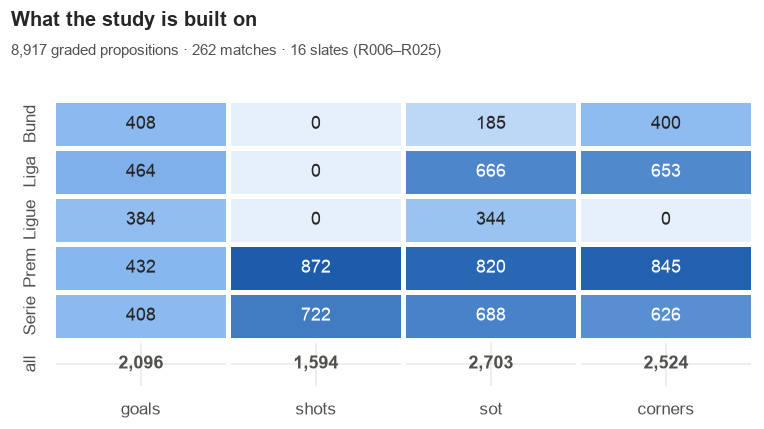

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_coverage.png')

In [3]:
fig = sp.coverage(s); sp.save(fig, "coverage")

## 2. Same-match correlation

Each proposition gets a standardised surprise, `z = (won − p) / √(p(1−p))`: positive if it landed and negative if it didn't, scaled by how surprising that was. For two propositions on the same match, the average of `z₁·z₂` estimates their correlation ρ.

- **ρ > 0:** they tend to land together. Two legs on one match then behave like fewer than two.
- **ρ < 0:** one landing makes the other less likely. A pair like that hedges itself.
- **Placebo:** the same estimator on pairs from *different* matches should give about 0. If it doesn't, the estimator is biased.

Intervals are **clustered by match**. Pairs on one match share propositions, so they are not independent evidence. The first study's `std/√n` treated them as if they were, which made its intervals roughly half as wide as they should have been.

Two samples are shown:
- **all priced:** every proposition the odds form priced. This gives the most pairs.
- **qualified only:** the `e ≥ 1` propositions the portfolio builder actually combines.

Both measure the same thing on different subsets, so a large gap between them would mean the result depends on which propositions are selected.

In [4]:
pairs = st.pair_frame(s)
pairs_q = st.pair_frame(s, qualified_only=True)
placebo = st.placebo_correlation(s)
print(f"{len(pairs):,} same-match pairs ({len(pairs_q):,} qualified) · placebo ρ̂ = {placebo['rho']:+.3f} ± {1.96*placebo['se']:.3f}")

211,229 same-match pairs (6,710 qualified) · placebo ρ̂ = +0.002 ± 0.015


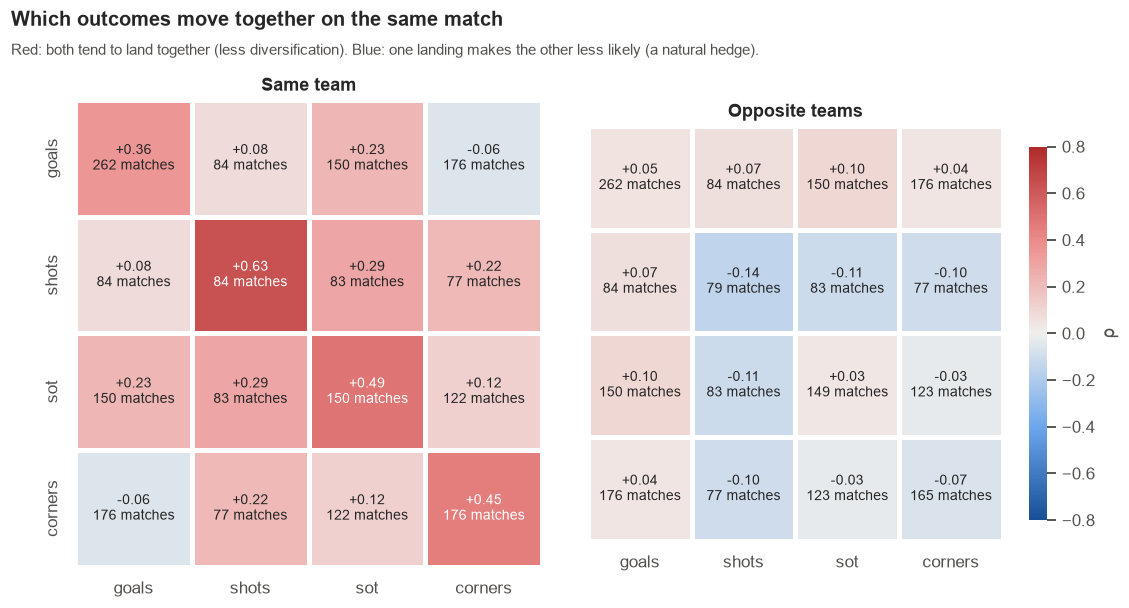

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_corr_heatmap.png')

In [5]:
fig = sp.correlation_heatmaps(pairs, st.rho_table); sp.save(fig, "corr_heatmap")

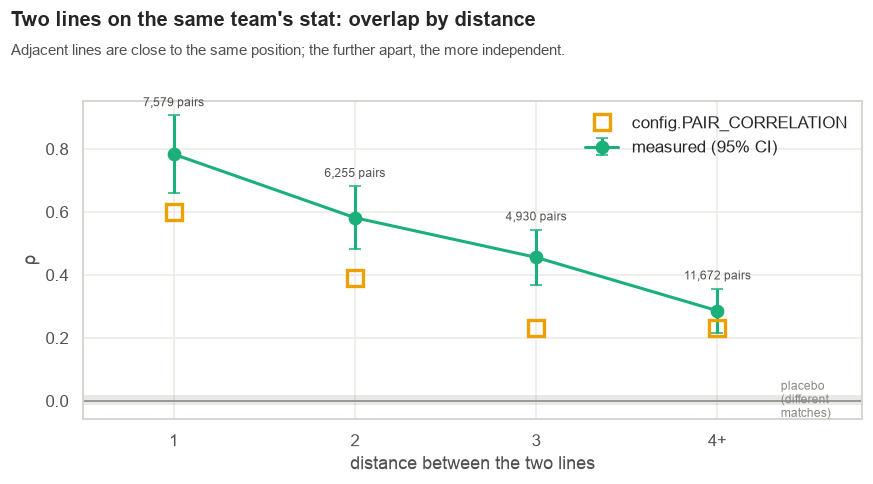

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_corr_by_gap.png')

In [6]:
fig = sp.correlation_by_gap(pairs, st.rho_table, placebo, config.PAIR_CORRELATION); sp.save(fig, "corr_by_gap")

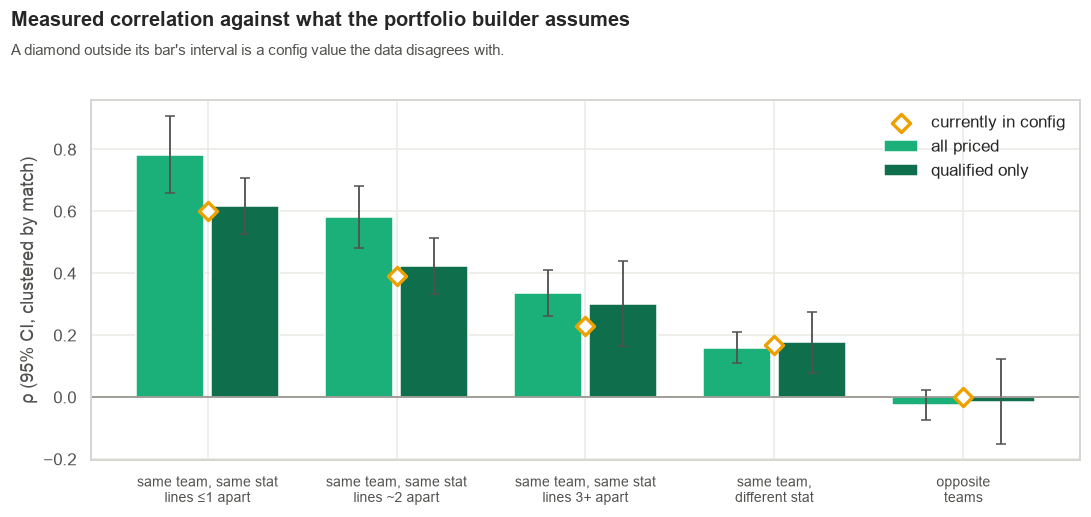

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_corr_vs_config.png')

In [7]:
compare = {"all priced": st.correlation_vs_config(pairs), "qualified only": st.correlation_vs_config(pairs_q)}
fig = sp.correlation_vs_config(compare); sp.save(fig, "corr_vs_config")

In [8]:
pd.concat(compare, names=["sample"]).droplevel(1)[["relation", "rho", "lo", "hi", "pairs", "matches", "configured", "differs"]]

,relation,rho,lo,hi,pairs,matches,configured,differs
sample,,,,,,,,
all priced,same_team_same_stat_adjacent,0.783,0.661,0.906,7579,262,0.600,True
all priced,same_team_same_stat_near,0.582,0.482,0.682,6255,262,0.390,True
all priced,same_team_same_stat_far,0.337,0.262,0.411,16602,262,0.230,True
all priced,same_team_diff_stat,0.160,0.110,0.210,73243,204,0.170,False
all priced,opposite_teams,-0.025,-0.073,0.023,107550,262,0.000,False
qualified only,same_team_same_stat_adjacent,0.617,0.527,0.707,1030,217,0.600,False
qualified only,same_team_same_stat_near,0.424,0.334,0.514,738,194,0.390,False
qualified only,same_team_same_stat_far,0.301,0.164,0.438,1065,150,0.230,False
qualified only,same_team_diff_stat,0.177,0.078,0.276,2623,112,0.170,False


## 3. Calibration: the model against the price

`market_p` is `1/odds` at the best price on the form. It still carries the market's margin, because the form only captures the Over side, so there's nothing to strip the overround against. That bias flatters the model, so if the model loses here, it genuinely loses.

Read the three charts in order:
1. **Reliability.** Does a 30% proposition land 30% of the time? Points above the dashed line are probabilities that were too low.
2. **Gap heatmap.** The same idea collapsed to one number per stat × league, so you can see *where* the error sits.
3. **Forest plot.** The model's log loss minus the market's, per proposition. Left of zero means the model priced better than the market.

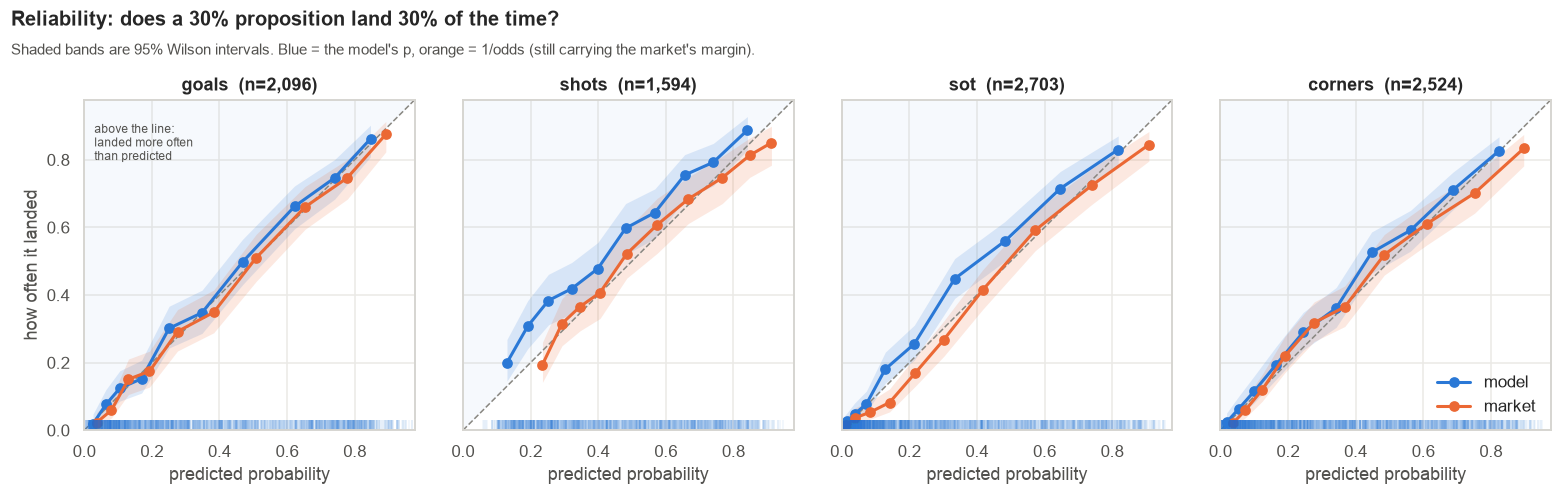

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_reliability.png')

In [9]:
fig = sp.reliability(st.reliability_frame(s, "target"), s); sp.save(fig, "reliability")

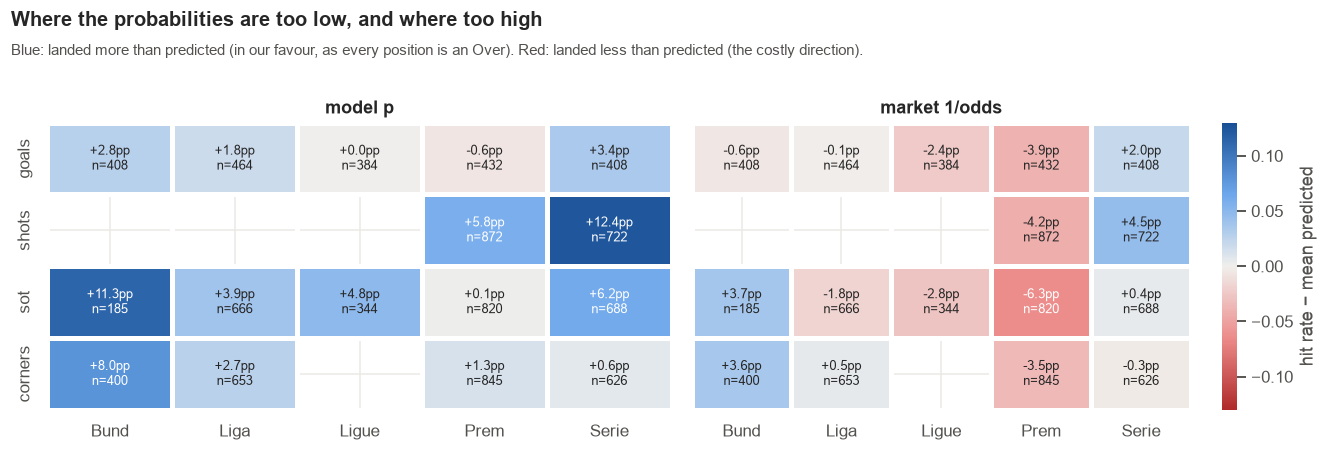

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_calibration_gap.png')

In [10]:
fig = sp.gap_heatmap({"model p": st.gap_table(s, source="p"), "market 1/odds": st.gap_table(s, source="market_p")})
sp.save(fig, "calibration_gap")

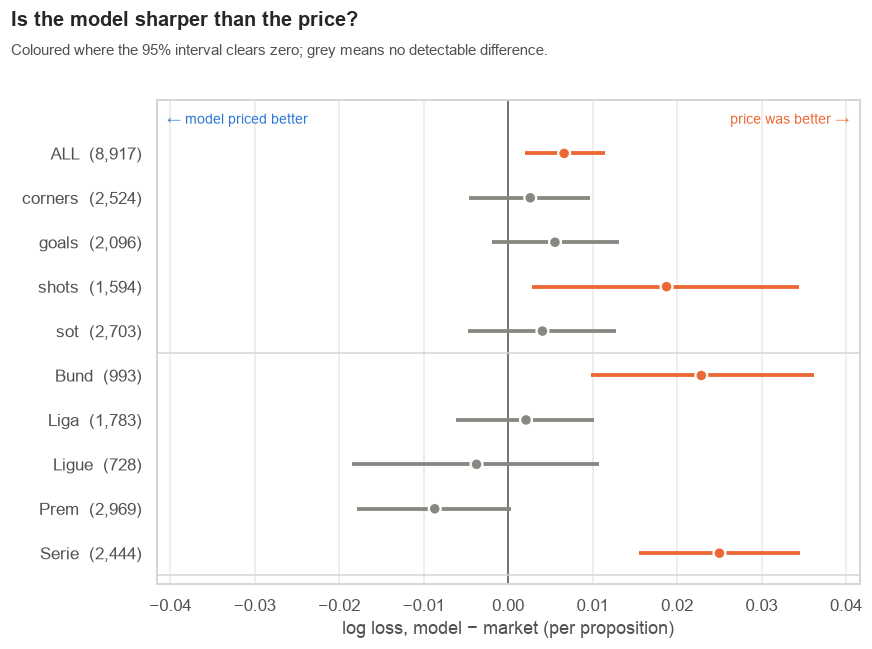

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_model_vs_market.png')

In [11]:
comp = st.market_comparison(s)
fig = sp.market_forest(comp); sp.save(fig, "model_vs_market")

In [12]:
comp[["grouping", "level", "n", "base_rate", "model_p", "market_p", "model_logloss", "market_logloss", "winner"]]

,grouping,level,n,base_rate,model_p,market_p,model_logloss,market_logloss,winner
0,all,all,8917,0.387,0.349,0.399,0.484,0.478,neither
1,target,corners,2524,0.370,0.345,0.375,0.489,0.487,neither
2,target,goals,2096,0.379,0.364,0.389,0.472,0.466,neither
3,target,shots,1594,0.546,0.458,0.549,0.611,0.592,market
4,target,sot,2703,0.316,0.276,0.339,0.415,0.411,neither
6,league,Bund,993,0.476,0.412,0.457,0.574,0.551,market
7,league,Liga,1783,0.343,0.314,0.348,0.448,0.446,neither
8,league,Ligue,728,0.350,0.328,0.376,0.421,0.425,neither
9,league,Prem,2969,0.373,0.353,0.419,0.475,0.484,neither
10,league,Serie,2444,0.411,0.349,0.394,0.505,0.480,market


### 3b. The positions actually taken

Overall calibration describes every proposition the form priced. The portfolio only ever takes positions in the ones with `p × odds ≥ 1`, and selecting on that condition picks out the rows where the model sits above the price. Those are disproportionately the rows where the model is too high. So check the qualified set separately: a constant that fixes the whole set can make the positions themselves worse.

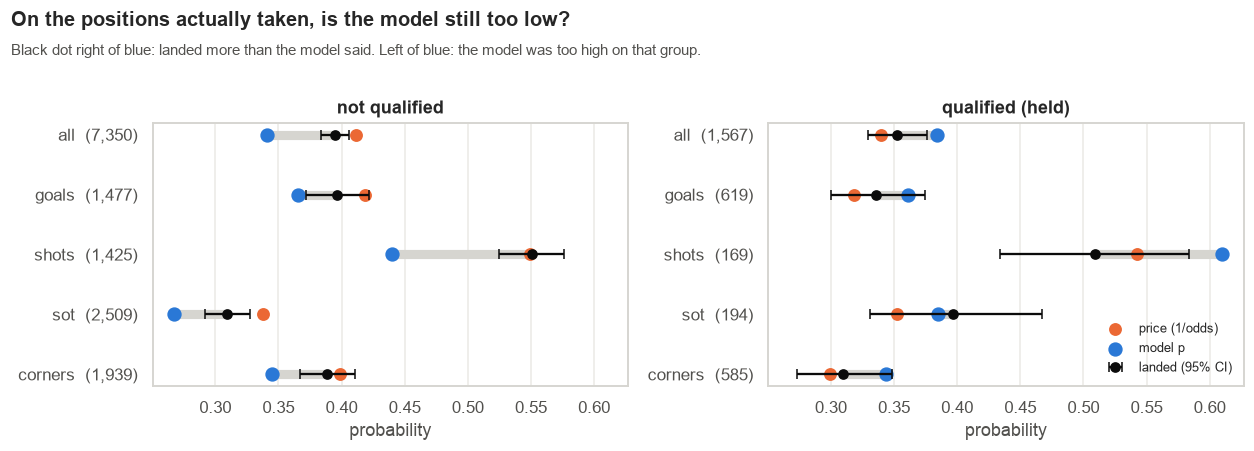

,qualified,n,hit_rate,hit_lo,hit_hi,model_p,market_p,gap_pp,flat_roi
0,not qualified,7350,0.395,0.383,0.406,0.341,0.411,5.343,-0.079
1,qualified (held),1567,0.352,0.329,0.376,0.384,0.340,-3.198,-0.014


In [13]:
sel, sel_by = st.selection_check(s), st.selection_check(s, "target")
fig = sp.selection(sel, sel_by); sp.save(fig, "selection")
sel

## 4. Should `p` be dampened or inflated?

The candidate adjustment is `logit p′ = a + b · logit p`:
- `b < 1` **dampens**: it pulls every probability towards 50%.
- `b > 1` **inflates**: it pushes them further from 50%.
- `a > 0` shifts every probability up without changing the spread.

A **contextual** constant lets `(a, b)` differ by target, league, venue, odds band or target × league. Each context's values are pulled back towards the global fit (a ridge penalty, its strength chosen inside each training fold), so a thin cell can't chase noise.

Every option is scored **leave-one-slate-out**: fit on every slate but one, score the held-out slate, and repeat for each slate. A constant that only improves the slates it was fitted on has learnt nothing. Gains are log loss per proposition. Positive means the adjustment helped, and the intervals resample whole matches.

Two benchmarks sit alongside:
- **use the price instead:** replace `p` with `1/odds`.
- **lean on the price:** add `logit(1/odds)` to the global fit.

The cross-validation takes about a minute.

In [14]:
cv = st.loso_predictions(s)
summary = st.recalibration_summary(cv)

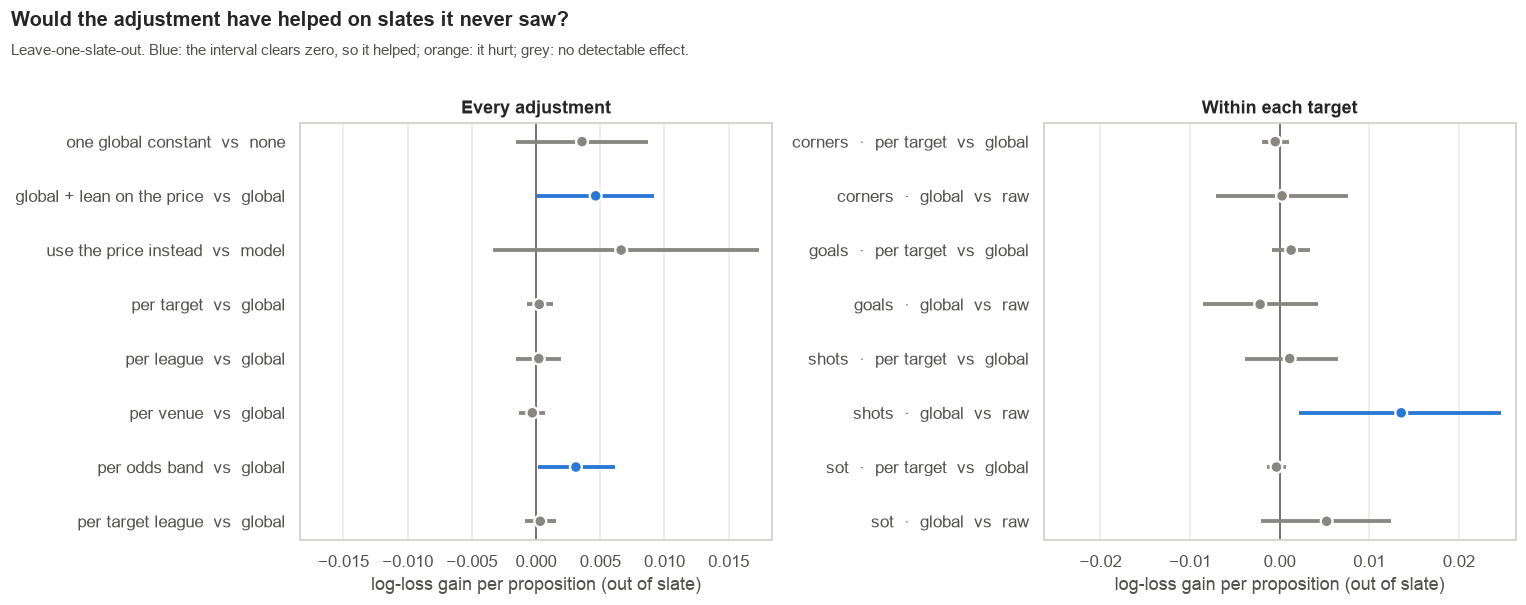

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_recalibration_cv.png')

In [15]:
fig = sp.recalibration_forest(summary, st.recalibration_by_level(cv, "target")); sp.save(fig, "recalibration_cv")

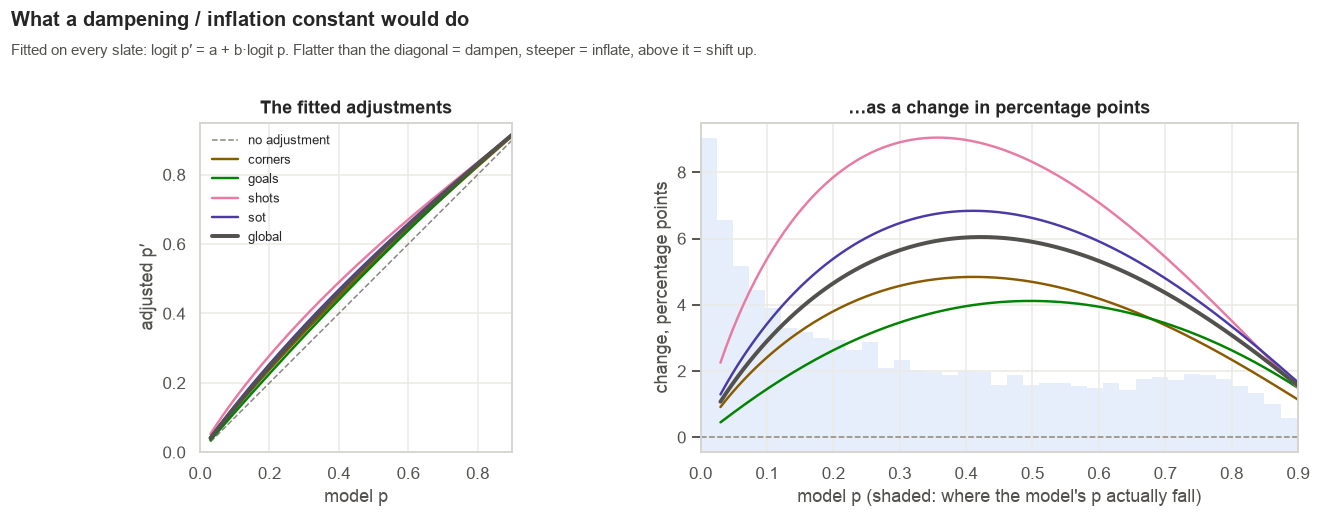

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_adjustment_curves.png')

In [16]:
glob, per_target = st.fitted_constants(s), st.fitted_constants(s, "target")
fig = sp.adjustment_curves(s, per_target, glob); sp.save(fig, "adjustment_curves")

In [17]:
pd.concat([glob, per_target], ignore_index=True)[["level", "n", "a", "b", "p_at_30", "p_at_50", "reads_as"]]

,level,n,a,b,p_at_30,p_at_50,reads_as
0,global,8917,0.237,0.977,0.356,0.559,"no spread change, shift up"
1,corners,2524,0.188,0.975,0.346,0.547,"no spread change, shift up"
2,goals,2096,0.165,1.006,0.335,0.541,"no spread change, shift up"
3,shots,1594,0.336,0.929,0.389,0.583,"dampen, shift up"
4,sot,2703,0.266,0.970,0.365,0.566,"dampen, shift up"


In [18]:
summary

,adjustment,versus,gain,lo,hi,logloss,helps,hurts
0,global,raw,0.004,-0.002,0.009,0.481,False,False
1,blend,global,0.005,0.000,0.009,0.476,True,False
2,market,raw,0.007,-0.003,0.017,0.478,False,False
3,per target,global,0.000,-0.001,0.001,0.481,False,False
4,per league,global,0.000,-0.002,0.002,0.481,False,False
5,per venue,global,-0.000,-0.001,0.001,0.481,False,False
6,per odds_band,global,0.003,0.000,0.006,0.478,True,False
7,per target_league,global,0.000,-0.001,0.002,0.481,False,False


### 4b. Push before selecting, deflate before sizing

Section 3b showed the catch with a straight push: it fixes the average but makes the positions themselves look better than they are. The two-step version:

1. **Push** before selection: `logit p ← logit p + k·(a + (b−1)·logit p)`. That's the calibration fit above, applied a fraction `k` of the way. `k = 0` is today's model and `k = 1` is the full fit.
2. **Deflate** before sizing: `p_stake = p_push − d`. `d` is how far the pushed p sat above the hit rate **on the propositions it selected**, so it measures selection bias directly. It's the same form as `config.PESSIMISM_B`.

**Nothing is fitted on the slate it's scored on.** For each held-out slate:
- an inner leave-one-slate-out over the other slates gives every training row a pushed p from a fit that never saw it;
- those rows give `d` for each `k`, and the `k` that grew capital best (`tuned`);
- the push is then refitted on the training slates and applied to the held-out one.

Selection is the real `p × odds ≥ 1` filter plus the within-match `(p, o)` frontier. **Sizing here is a stand-in**: quarter-Kelly per position, scaled so that one slate never risks more than 20% of capital. It doesn't build portfolios, and it ignores the two-per-match limit and correlation, so section 4c re-scores the leading strategies through the real builder. Growth, rather than summed profit, is what's scored, because summed profit rewards larger positions and so rewards over-confident probabilities.

This takes about 10 seconds.

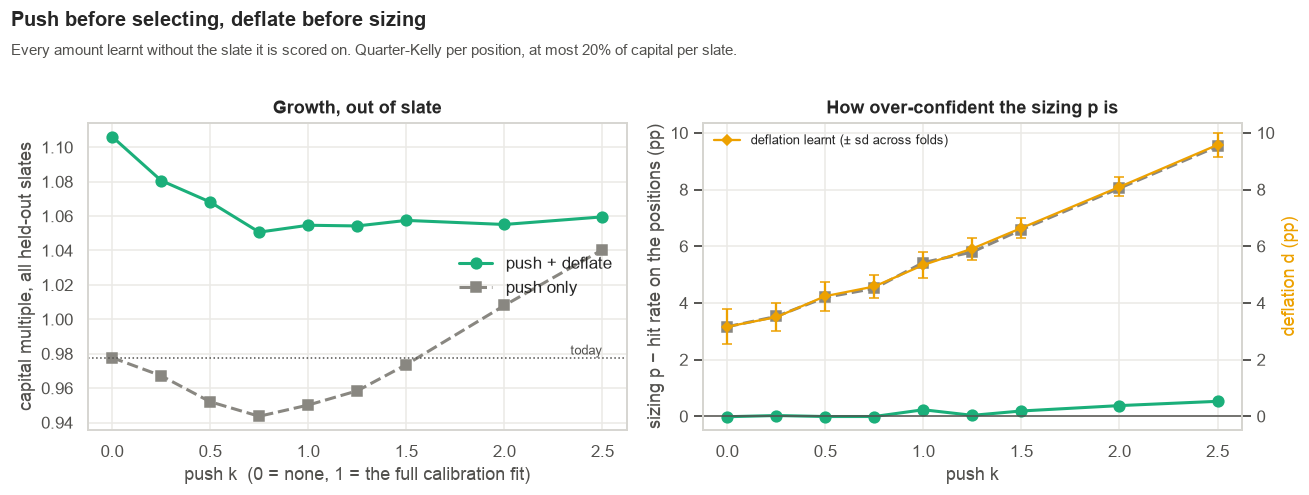

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_push_deflate.png')

In [19]:
bt, tuning = st.push_deflate_backtest(s)
bt_sum = st.backtest_summary(bt)
fig = sp.push_deflate(bt_sum, tuning); sp.save(fig, "push_deflate")

In [20]:
bt_sum[["strategy", "mean_deflate", "positions", "sized_positions", "said", "landed", "flat_roi", "capital_x", "gain_lo", "gain_hi", "slates_better", "slates_worse"]]

,strategy,mean_deflate,positions,sized_positions,said,landed,flat_roi,capital_x,gain_lo,gain_hi,slates_better,slates_worse
0,k=0 push only,0.000,1566,1566,0.384,0.352,-0.013,0.978,0.000,0.000,0,0
1,k=0 push+deflate,0.028,1566,754,0.352,0.352,-0.013,1.106,-0.127,0.372,9,4
2,tuned,0.052,2398,1146,0.368,0.359,-0.089,0.932,-0.235,0.107,6,7
3,k=0.25 push only,0.000,1820,1820,0.392,0.357,-0.015,0.967,-0.070,0.060,5,8
4,k=0.25 push+deflate,0.031,1820,894,0.357,0.357,-0.015,1.081,-0.081,0.284,9,4
5,k=0.5 push only,0.000,2074,2074,0.399,0.357,-0.028,0.952,-0.135,0.096,4,9
6,k=0.5 push+deflate,0.037,2074,957,0.357,0.357,-0.028,1.068,-0.058,0.239,9,4
7,k=0.75 push only,0.000,2319,2319,0.407,0.362,-0.023,0.944,-0.182,0.126,5,9
8,k=0.75 push+deflate,0.040,2319,1106,0.362,0.362,-0.023,1.051,-0.015,0.165,8,5
9,k=1 push only,0.000,2546,2546,0.415,0.361,0.005,0.950,-0.209,0.168,7,8


In [21]:
print("k chosen per held-out slate:", tuning["k_chosen"].value_counts().sort_index().to_dict())
tuning.filter(like="d@").agg(["mean", "std"]).mul(100).round(1)   # deflation in pp, across folds

k chosen per held-out slate: {0.0: 10, 2.0: 1, 2.5: 5}


,d@0,d@0.25,d@0.5,d@0.75,d@1,d@1.25,d@1.5,d@2,d@2.5
mean,3.200,3.500,4.200,4.600,5.300,5.900,6.600,8.100,9.600
std,0.600,0.500,0.500,0.400,0.400,0.400,0.300,0.300,0.400


### 4c. The same strategies through the real portfolio builder

Each held-out slate goes through exactly what `06_Split` does:
1. `portfolio.search`: qualify, at most two legs per match with pairs priced using `PAIR_CORRELATION`, growth split, dominance.
2. The 06 pick rule: expected return ≥ 1.05, P(profit) ≥ 0.70, spread ≤ 0.25, then the highest P(profit).
3. The position size from `growth_metrics` and `suggested_fraction`, with each strategy's deflation going in through the `PESSIMISM_B` hook.

The push and deflation are learnt at proposition level on the other slates, as in 4b. The strategies:

| Strategy | Builder selects on | Deflation at sizing |
|---|---|---|
| today | raw p | none |
| deflate all | raw p | pooled, ~2pp |
| shots shift by league, no deflation | shots shifted per league (partially pooled): **the production rule** | none |
| shots shift pooled, no deflation | shots shifted by one pooled amount | none |
| shots push, no deflation | shots pushed to the calibration fit | none |
| shots push, deflate others | shots pushed to the calibration fit | 0 on shots, ~2pp on the other three |
| shots push, deflate all | shots pushed | pooled, every leg |
| half push all, deflate all | every stat pushed half-way | pooled |

Each slate is replayed **as it was run**: the 13 matchday slates, with R018 dropped because R019 re-ran it. The push and deflation for a slate are learnt on the other slates' rows, with that slate's matches removed, so overlapping re-runs can't leak a result.

The full search takes ~15 minutes per slate at `portfolio.GRID` = 16,384. The replay uses 2,048, which on R020 picked the identical portfolio, position size and return as the full grid. A fresh run takes ~30–50 minutes on 4 cores, so the result is cached. Pass `refresh=True` once new slates are graded.

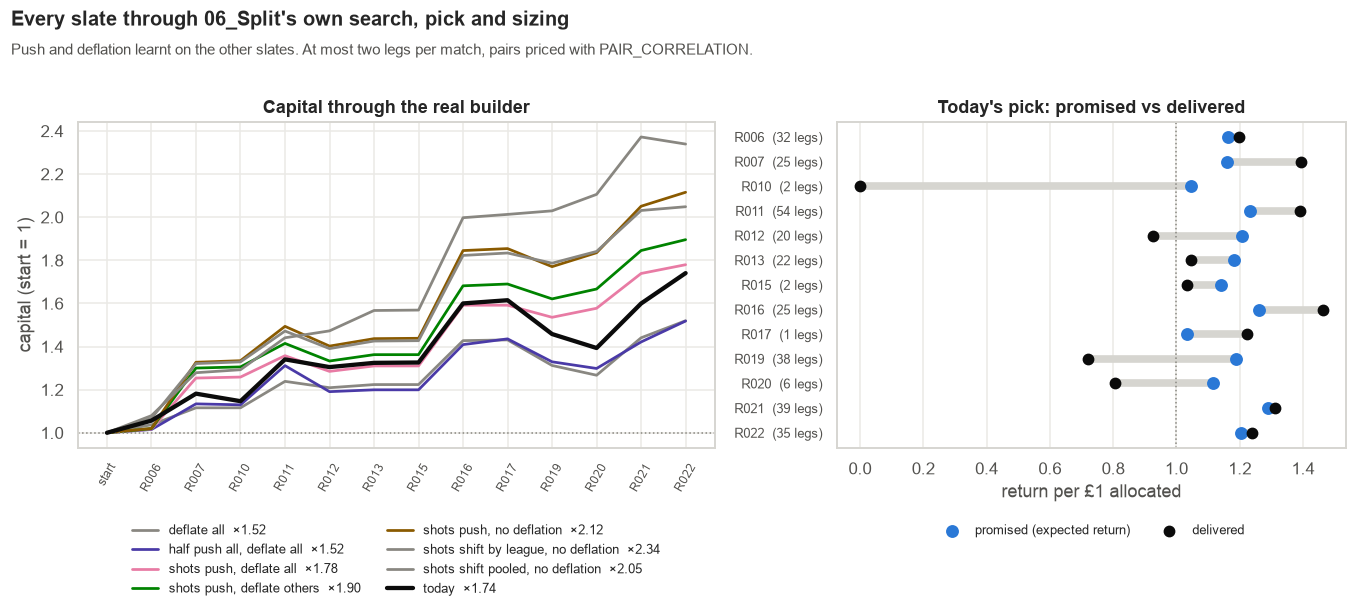

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_portfolio_replay.png')

In [22]:
from fpp.paths import ANALYSIS_REPORTS
replay = st.portfolio_backtest(s, cache=ANALYSIS_REPORTS / "portfolio_backtest.parquet")
fig = sp.portfolio_replay(replay); sp.save(fig, "portfolio_replay")

In [23]:
st.portfolio_summary(replay)[["strategy", "mean_legs", "mean_shots_legs", "mean_f", "mean_R", "mean_expected_R", "capital_x", "gain_lo", "gain_hi", "slates_better", "slates_worse"]]

,strategy,mean_legs,mean_shots_legs,mean_f,mean_R,mean_expected_R,capital_x,gain_lo,gain_hi,slates_better,slates_worse
0,"shots shift by league, no deflation",28.385,8.462,0.390,1.167,1.249,2.339,0.907,1.931,8,4
1,"shots push, no deflation",29.615,8.692,0.362,1.160,1.229,2.116,0.827,1.845,6,6
2,"shots shift pooled, no deflation",29.077,9.077,0.385,1.146,1.215,2.049,0.805,1.701,7,5
3,"shots push, deflate others",29.615,8.692,0.312,1.160,1.229,1.896,0.746,1.623,6,7
4,"shots push, deflate all",29.615,8.692,0.279,1.160,1.229,1.780,0.716,1.471,6,7
5,today,23.154,0.692,0.283,1.058,1.171,1.741,1.000,1.000,0,0
6,deflate all,23.154,0.692,0.212,1.058,1.171,1.520,0.741,1.024,4,9
7,"half push all, deflate all",36.923,0.923,0.309,1.017,1.242,1.518,0.713,1.054,4,9


### 4d. Three legs per match

The rulebook (`config.TRIPLES_ENABLED`, switched on 14 Oct):
1. Never two legs on the same team and the same stat.
2. Opposite-team pairs are always allowed.
3. Never all three legs on one team.

That leaves one shape: two legs on one team, on different stats, plus one leg on the other team. The triple is priced from its three pairwise correlations (`portfolio.block_joint`).

Each slate runs **as it was actually run** (no deduplication; R018 is dropped because R019 re-ran it). It goes through the builder twice, triples off and on, and the 06 pick and the whole frontier are settled against results. A fresh run takes ~25 minutes, so it is cached.

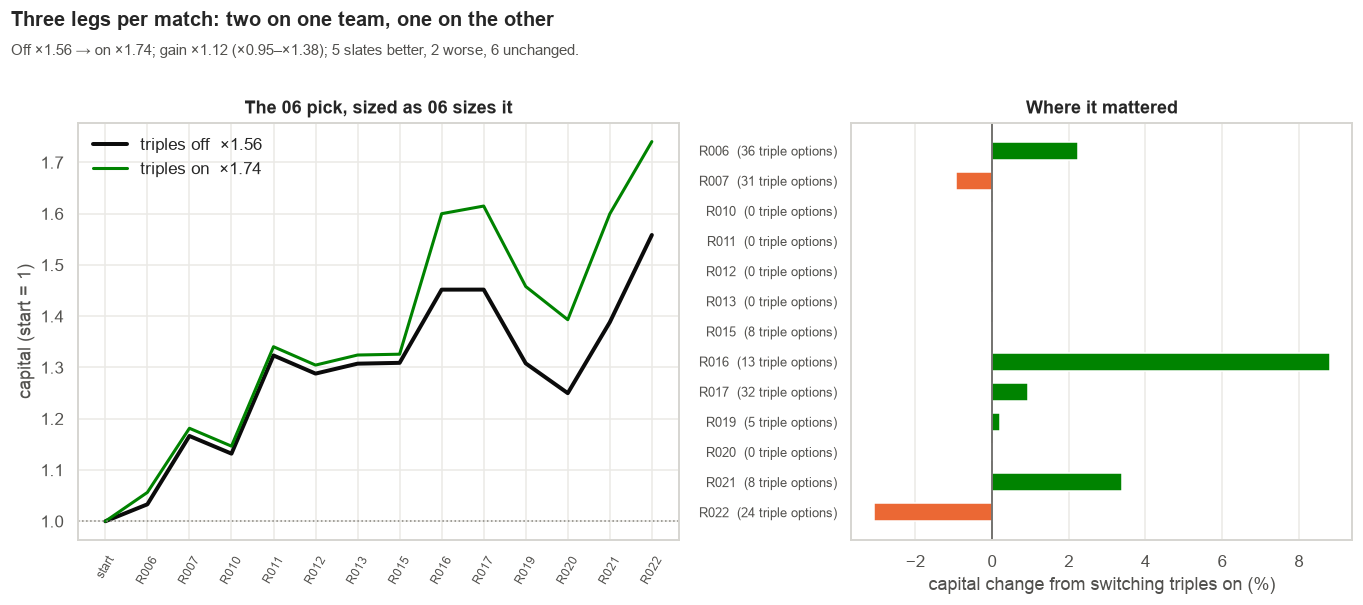

,matches,triple_options,pick_triples,legs_off,legs_on,R_off,R_on,growth_off,growth_on,front_med_off,front_med_on
slate,,,,,,,,,,,
R006,22.000,36.000,2.000,30.000,32.000,1.117,1.199,0.033,0.055,1.039,1.025
R007,15.000,31.000,2.000,23.000,25.000,1.444,1.392,0.121,0.112,2.295,2.187
R010,5.000,0.000,0.000,2.000,2.000,0.000,0.000,-0.030,-0.030,0.605,0.605
R011,45.000,0.000,0.000,54.000,54.000,1.391,1.391,0.156,0.156,1.408,1.408
R012,24.000,0.000,0.000,20.000,20.000,0.925,0.925,-0.027,-0.027,0.914,0.914
R013,21.000,0.000,0.000,22.000,22.000,1.046,1.046,0.015,0.015,1.182,1.182
R015,3.000,8.000,0.000,2.000,2.000,1.034,1.034,0.001,0.001,1.743,1.779
R016,14.000,13.000,2.000,20.000,25.000,1.257,1.463,0.104,0.188,1.382,1.433
R017,13.000,32.000,0.000,2.000,1.000,1.001,1.222,0.000,0.009,1.380,1.422


In [24]:
tb = st.triples_backtest(cache=ANALYSIS_REPORTS / "triples_replay.parquet")
tsum = st.triples_summary(tb)
fig = sp.triples_replay(tsum); sp.save(fig, "triples_replay")
tsum.round(3)

### 4e. The per-leg cap, across every viable portfolio

`MAX_LEG_STAKE` = 15%, loosened to 2 ÷ legs on short portfolios (`CAP_RELIEF`). Every undominated portfolio on every slate is re-weighted at each cap and settled; the legs stay fixed. This shows what the cap does to the weights, not which portfolio the pick would then choose. The run is cached.

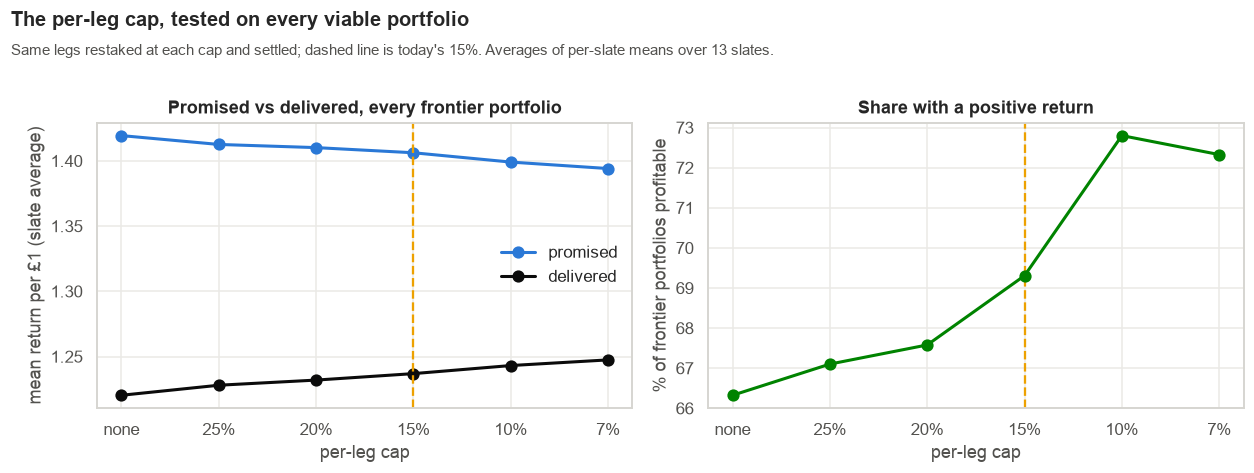

PosixPath('/Users/patrickknott/Developer/proposition-portfolio/Outputs/Analysis/Reports/Figures/study_leg_cap.png')

In [25]:
lc = st.leg_cap_backtest(cache=ANALYSIS_REPORTS / "leg_cap_replay.parquet")
fig = sp.leg_cap(lc); sp.save(fig, "leg_cap")

### 4f. A 10% leg cap, through the full builder

4e held the legs fixed. Here the cap is in force **during** the search, so dominance and the 06 pick can respond to it. Every slate is replayed at 15% and at 10%, with triples on, and settled. The run is cached (~35 minutes fresh).

In [26]:
cr = st.leg_cap_replay(cache=ANALYSIS_REPORTS / "leg_cap_full_replay.parquet")
st.leg_cap_summary(cr)

,cap,pick_capital_x,gain_vs_baseline,gain_lo,gain_hi,slates_better,slates_worse,frontier_delivered,frontier_promised,frontier_profitable
0,0.150,1.741,1.000,1.000,1.000,0,0,1.236,1.403,0.691
1,0.100,1.711,0.983,0.900,1.073,3,5,1.228,1.404,0.698


### 4g. The production shots shift

From 14 Oct, `config.SHOTS_LOGIT_SHIFT` adds a per-league shift to the logit of every shots team-line probability. It is applied in `report.markets.fixture_markets`, which 05 uses for the predictions workbook, the odds form and the Edge Book. The model's own value is kept beside it, as `..._raw` there and as `p_raw` in the ledger, so calibration can be tracked on both. The odds form and `run.json` record the shift that was applied.

The fit below is what to refit as slates accumulate. It always runs on `p_raw`, so it measures the model rather than the model plus the last shift. The monitor underneath follows live runs: if the shift is right, `gap_shifted` sits near zero while `gap_raw` stays positive.

In [27]:
fit = st.shots_shift(s)
print("per league:", fit["shift"], " pooled:", fit["pooled"], " ridge:", fit["ridge"], " n:", fit["n"])
print("out-of-slate log loss:", {k: round(float(v), 4) for k, v in fit["cv_logloss"].items()})
print("in config:            ", config.SHOTS_LOGIT_SHIFT, " default:", config.SHOTS_LOGIT_SHIFT_DEFAULT)

per league: {'Prem': 0.368, 'Serie': 0.687}  pooled: 0.528  ridge: 30.0  n: {'Prem': 872, 'Serie': 722}
out-of-slate log loss: {'raw': 0.6114, 'pooled': 0.5904, 'per_league': 0.5884}
in config:             {'Prem': 0.389, 'Serie': 0.728}  default: 0.558


In [28]:
st.shift_monitor(s)

,run_code,league,n,hit_rate,p_raw,p,gap_raw,gap_shifted
0,R025,Prem,107,0.523,0.478,0.554,0.045,-0.031
1,R025,Serie,86,0.535,0.463,0.605,0.072,-0.070


### 4h. Same team, same stat in pairs

From 16 Oct, `config.PAIR_SAME_TEAM_STAT` is off: a pair can no longer hold two lines on the same team's same statistic, matching the triple rulebook. Both legs of such a pair are read off one predicted mean, so an error in that estimate hits both. That shared model error isn't captured by the measured outcome correlation the builder prices.

Each slate as run is replayed with the rule off and on, under production settings: triples on, and the shots shift fitted on the other slates. Cached; ~25 minutes fresh.

In [29]:
prr = st.pair_rule_backtest(cache=ANALYSIS_REPORTS / "pair_rule_replay.parquet")
prs = st.pair_rule_summary(prr)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in prs.attrs.items()})
prs

{'gain': 0.917, 'gain_lo': 0.744, 'gain_hi': 1.121, 'better': 4, 'worse': 6, 'same': 3}


,same_team_same_stat_pairs,pick_capital_x,pick_mean_R,pick_mean_legs,frontier_delivered,frontier_profitable
0,banned,2.145,1.159,26.462,1.227,0.766
1,allowed,2.339,1.167,28.385,1.187,0.754


### 4i. Which portfolio to choose off the frontier

Every exported portfolio on every graded slate is scored against what actually happened. Each portfolio is ranked within its own slate, so 0.5 means "as good as the median portfolio".

A rule keeps the portfolios whose within-slate percentile on one measure, or two, falls in a band at least 20 points wide. That's about 73,000 rules. The search itself is tested **leave-one-slate-out**: choose the best rule on the other slates, score it on the held-out one. Only rules that keep winning there hold up.

In [30]:
fr = st.score_frontiers()
scores = st.rule_search(fr)
complete = scores[scores.notna().all(axis=1)]
singles = complete[complete.index.get_level_values("m2") == ""]
for name, sub in (("every single + pair rule", complete), ("single-measure rules", singles)):
    H = st.rule_holdout(sub)
    print(f"{name:26s} held-out mean {H.held_out_score.mean():.3f}, above median on {int((H.held_out_score > .5).sum())}/{len(H)}; "
          f"chosen: {H.rule.map(st.describe_rule).value_counts().to_dict()}")

every single + pair rule   held-out mean 0.485, above median on 6/10; chosen: {'capacity 20-40% & sd_pct 80-100%': 4, 'g_p0 70-90% & median_leg_p 30-80%': 3, 'capacity 20-90% & p_over_100 0-20%': 1, 'p_over_100 10-30% & legs 10-30%': 1, 'p_over_100 20-40% & sd_pct 80-100%': 1}
single-measure rules       held-out mean 0.625, above median on 8/10; chosen: {'expected_return_pct 70-90%': 9, 'g_p0 70-90%': 1}


In [31]:
best = singles.assign(mean=singles.mean(axis=1), above=(singles > .5).sum(axis=1), worst=singles.min(axis=1))
best = best.sort_values("mean", ascending=False).head(8)[["mean", "above", "worst"]]
best.index = [st.describe_rule(r) for r in best.index]
best.round(3)

,mean,above,worst
expected_return_pct 70-90%,0.642,8,0.303
sd_pct 70-90%,0.639,8,0.304
g_p0 70-90%,0.635,8,0.410
g_p0 60-90%,0.611,8,0.415
expected_return_pct 60-90%,0.607,8,0.310
sd_pct 60-90%,0.607,8,0.310
median_leg_p 10-30%,0.606,8,0.399
median_leg_p 10-40%,0.598,8,0.413


## 5. Findings — run of 14 Oct 2026

Based on 7,872 graded propositions from 237 matches and 14 slates (R006–R022, after duplicate re-runs were removed). Every number below changes as slates accumulate, so re-run this rather than quoting it. Intervals are 95% and clustered by match unless stated otherwise.

**Same-match correlation**
- **Same team, same stat:** correlation falls as the lines move apart: 0.60 / 0.39 / 0.23 on the positions actually combined (the first study had 0.63 / 0.40 / 0.30).
- **Same team, different stat:** 0.15–0.17 overall, against 0.267 in the first study. It has real structure:

  | Same-team pair | ρ |
  |---|---|
  | shots × SOT | 0.30 |
  | goals × SOT | 0.24 |
  | shots × corners | 0.19 |
  | SOT × corners | 0.10 |
  | goals × shots | 0.07 |
  | goals × corners | −0.05 |

  A per-stat-pair config would describe this better than one number.
- **Opposite teams:** about 0 for every stat pair.
- **Config updated 14 Oct** to the qualified-sample values: 0.60 / 0.39 / 0.23 / 0.17 / 0.0. Section 4c's cached replay predates that change, so refresh it next time.

**Calibration**
- **The model is too low on every stat, clearly so on two:**

  | Stat | Hit rate − mean p | 95% interval |
  |---|---|---|
  | shots | +10.7pp | [+5.6, +15.8] |
  | SOT | +4.2pp | [+1.1, +7.3] |
  | corners | +2.6pp | [−0.6, +5.8] |
  | goals | +2.2pp | [−0.4, +4.9] |

  Binned, shots is low in every bin. Slopes are about 1: the spread is right and the level is low.
- **Against the price:** level overall. The model is better in the Premier League and worse in the Bundesliga and Serie A.
- **On the positions actually taken the sign flips,** because of selection bias. Mean p is 0.370 against a 0.351 hit rate, i.e. **−2.0pp [−5.9, +2.0]**, so it isn't established on its own.
  - By stat: shots −5.7pp (n = 81), corners −2.7, goals −1.8, SOT +0.8.
  - Those positions still beat the market price: 35.1% landed against 32.8% implied by 1/odds.
- **The same bias shows up in portfolio expected returns, but the picks still returned a profit** (4c, slates as run):
  - On average, today's 06 picks promised **+17%** per slate and delivered **+6%**.
  - Leaving out the four 1–2-leg picks, they promised +20% and delivered **+15%**.
  - Weighted by position size, they delivered about 80% of what they promised.
  - Read the Edge Book's expected return as a few points high, not as a loss.

**Dampen, inflate, push, deflate**
- **No contextual constant beats one global constant** out of slate. The global constant (a straight shift up) is not significant on its own, except within shots.
- **Stand-in sizing (4b):** deflation makes the sizing p honest at every push level. Pushing without deflating always loses.
- **Real builder (4c), the test that matters.** Slates as run, current config, triples on:

  | Strategy | Capital multiple | Worst drawdown |
  |---|---|---|
  | **shots shift by league, no deflation (in production since 14 Oct)** | **×2.34** | **−1.4%** |
  | shots push, no deflation | ×2.12 | −6.1% |
  | shots shift pooled, no deflation | ×2.05 | −5.5% |
  | shots push, deflate the other three | ×1.90 | −5.8% |
  | shots push, deflate all | ×1.78 | −5.4% |
  | **today** | **×1.74** | −13.7% |
  | deflate all | ×1.52 | −11.5% |
  | half push all, deflate all | ×1.52 | −9.6% |

  - The production rule beats today on 8 slates and trails on 4, with a range of ×0.91 to ×1.93 against today. It's the strongest result in this notebook, but the interval still just includes "no difference".
  - All three shots-push variants select the same portfolios; they differ only in position size. Without deflation the mean size is 0.36 of capital against 0.28 today, so most of the extra growth comes from **taking larger positions on portfolios that returned more per £1**. Larger sizes also mean larger drawdowns when the edge isn't there.
  - The shots push is the only strategy that improves the positions themselves: portfolios returned **1.16 per £1 against 1.06** today, with about 9 shots legs each. That's the second replay in a row where it does.
  - **Deflating alone does worse** (4 better, 9 worse). The drawdown-limited position size is already conservative, and deflation mostly shrank positions on slates that returned a profit.
  - The half push looked level with today in the first replay (×1.37 against ×1.34). Run on the slates as you actually ran them, it falls behind.

**Builder changes tested through the replay**
- **Triples (4d), now on.** The 06 pick's capital multiple went ×1.56 with triples off to **×1.74** with them on, a gain of ×1.12 with a range of ×0.95 to ×1.38.
  - 5 slates did better, 2 worse, and 6 were unchanged because no valid triple was offered.
  - The whole frontier's median delivered return barely moved (+0.002).
  - Triples are rare (0–36 options a slate). On any one slate the difference is luck at the margin: switching them on lets the search re-pick a few legs, about 5–7% of the allocation.
- **Per-leg cap (4e), keep 15%.**
  - On normal slates no match carries more than about 23% of the allocation, pairs and triples included, so a per-match cap isn't needed.
  - Across every frontier portfolio, tighter caps delivered slightly more and promised slightly less:

    | Cap | Delivered | Promised | Share profitable |
    |---|---|---|---|
    | none | 1.220 | 1.419 | 66% |
    | 15% | 1.237 | 1.406 | 69% |
    | 10% | 1.243 | 1.399 | 73% |

  - That direction is consistent with trimming over-rated heavy legs, but slate by slate it splits 7 to 6. 10% is worth re-testing when there's more data.
  - The concentration that does happen is on 1–2-leg picks (R010, R015, R017), where `CAP_RELIEF` uncaps the row. That's a pick-rule problem, not a cap problem.
- **10% cap through the full builder (4f): no.**
  - The 06 pick's capital multiple was ×1.71 at 10% against ×1.74 at 15%, with 3 slates better, 5 worse and 5 the same.
  - The frontier mean delivered 1.228 against 1.236.
  - The fixed-legs hint in 4e didn't survive once the search and pick could respond.
  - On R007 the tighter cap pushed the big portfolios under the P(profit) 0.70 filter, so the rule fell back to a 4-leg pick. The pick rule's weakness again.

- **Same team, same stat in pairs (4h), off since 16 Oct.**
  - The 06 pick's capital multiple was ×2.15 with these pairs banned, against ×2.34 with them allowed: a ratio of ×0.92, range ×0.74 to ×1.12. 4 slates were better, 6 worse and 3 the same.
  - The whole frontier did slightly better with the ban: mean delivered 1.227 against 1.187, and 76.6% of portfolios profitable against 75.4%.
  - Both differences are within noise. The rule is kept as a risk choice, because the shared model error it guards against is the kind a 13-slate replay can't show. Revisit if the pick keeps trailing.

- **Choosing off the frontier (4i).**
  - Searching every percentile-band rule on nine portfolio measures (about 73,000 rules) **overfits**. The best rule chosen on 9 slates scored 0.485 on the held-out slate, worse than the median portfolio.
  - **Single-measure rules hold up:** the one chosen on 9 slates beat the median on 8 of 10 held-out slates.
  - **"Promised return in the 70th–90th percentile of the frontier" was chosen in all ten folds.** It scored 0.642, and its portfolios grew capital ×1.53 at suggested size against ×1.43 for the median portfolio.
  - **Refined in 5-point steps, the 75th–85th percentile was chosen in all ten folds.** It beat the median on 9 of 10 held-out slates (0.670). Performance plateaus across 75–85% and falls away sharply above 95%.
  - **Wipe-out risk in the 75–85% band is small.** 1.3% of its portfolios returned nothing, all on one small slate (R020), where few-leg portfolios were sized at 7–9% of capital. Its worst hit to capital, −9%, was the mildest of any band.
  - **The top of every "safe-looking" measure underperforms:** capacity, P(profit), low wipe-out probability, likely legs. So does the very top of promised return, where the top 1% returned nothing on 7 of 10 slates.
  - The Edge Book's **"promised 75–85% band"** button applies the rule.

**Recommendations**
1. **Keep `PESSIMISM_B = 0`.** This replaces the earlier proposal of 0.02, which came from the stand-in sizing and didn't survive the real builder.
2. **Shots shift: in production from 14 Oct** (4g). Per-league logit shifts of 0.389 (Prem) and 0.728 (Serie), with no deflation. Raw and shifted values are both recorded. Refit on `p_raw` from 4g as slates accumulate, and watch `shift_monitor`.
3. **Keep `MAX_LEG_STAKE` at 15%.**
4. **Next experiments** (triples and the leg cap are now done):
   - per-stat-pair correlations in `PAIR_CORRELATION`;
   - a minimum leg count in the 06 pick rule, so it stops picking 1–2-leg portfolios;

**Caveats**
- `market_p` carries the market's margin.
- The effective sample is 13–14 slates, not thousands of rows.
- The real-builder replays use a 2,048-point return grid, validated on one slate.
- Runs captured from 14 Oct carry a model stamp (version, artifact fingerprint, hashes) in `run.json`. Filter on it with `load_study_set(model_version=...)`.
- Market-comparison intervals come from `analysis.model_vs_market` and resample rows rather than matches.